# Financial Fraud Detection - Model Training

## Objective

The objective of this notebook is to develop and evaluate
machine learning models for credit card fraud detection.

The following algorithms will be investigated:

- Logistic Regression
- Random Forest
- XGBoost

Model performance will be evaluated using metrics suitable
for highly imbalanced datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")

df["Hour"] = (df["Time"] // 3600) % 24
df["Log_Amount"] = np.log1p(df["Amount"])

X = df.drop(columns=["Class"])
y = df["Class"]

print("Dataset shape:", df.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (284807, 33)
Features shape: (284807, 32)
Target shape: (284807,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nFraud percentage in training set:")
print(round(y_train.mean() * 100, 4), "%")

print("\nFraud percentage in test set:")
print(round(y_test.mean() * 100, 4), "%")

Training set: (227845, 32)
Test set: (56962, 32)

Fraud percentage in training set:
0.1729 %

Fraud percentage in test set:
0.172 %


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create model pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [5]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Predictions
y_pred = logistic_model.predict(X_test)
y_proba = logistic_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("PR-AUC:", average_precision_score(y_test, y_proba))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.91      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.94      0.55     56962
weighted avg       1.00      0.97      0.99     56962

Confusion Matrix:
[[55375  1489]
 [    9    89]]
PR-AUC: 0.7240919224024291
ROC-AUC: 0.9733318235848081


## Threshold Optimization

The classification threshold will be evaluated on a validation
set to balance fraud detection and false positive rates.

The test set will remain untouched until final evaluation.

In [6]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_fit.shape)
print("Validation:", X_val.shape)

Training: (182276, 32)
Validation: (45569, 32)


In [7]:
validation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

validation_model.fit(X_fit, y_fit)

print("Validation model trained successfully!")

Validation model trained successfully!


In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_val_proba = validation_model.predict_proba(X_val)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1": f1_score(y_val, y_val_pred)
    })

threshold_results = pd.DataFrame(results)
threshold_results.round(3)

,Threshold,Precision,Recall,F1
0,0.1,0.010,0.949,0.021
1,0.2,0.020,0.924,0.039
2,0.3,0.031,0.911,0.059
3,0.4,0.043,0.899,0.082
4,0.5,0.058,0.886,0.108
5,0.6,0.077,0.873,0.141
6,0.7,0.104,0.848,0.185
7,0.8,0.140,0.835,0.240
8,0.9,0.193,0.835,0.314


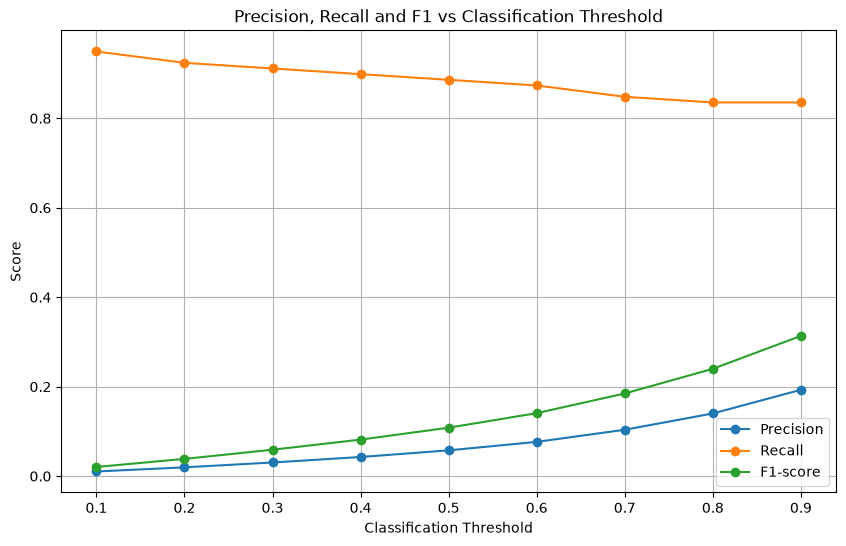

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Classification Threshold")
plt.legend()
plt.grid()
plt.show()

In [10]:
fine_thresholds = [
    0.90, 0.92, 0.94, 0.95,
    0.96, 0.97, 0.98, 0.99
]

fine_results = []

for threshold in fine_thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred
    ).ravel()

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1": f1_score(y_val, y_val_pred),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn
    })

fine_threshold_results = pd.DataFrame(fine_results)

fine_threshold_results.round(3)

,Threshold,Precision,Recall,F1,True Positives,False Positives,False Negatives
0,0.90,0.193,0.835,0.314,66,276,13
1,0.92,0.212,0.823,0.338,65,241,14
2,0.94,0.237,0.810,0.367,64,206,15
3,0.95,0.258,0.810,0.391,64,184,15
4,0.96,0.287,0.810,0.424,64,159,15
5,0.97,0.318,0.810,0.457,64,137,15
6,0.98,0.368,0.810,0.506,64,110,15
7,0.99,0.481,0.797,0.600,63,68,16


In [11]:
# Final model trained on the full training set
final_logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

final_logistic_model.fit(X_train, y_train)

print("Final Logistic Regression model trained!")

Final Logistic Regression model trained!


In [12]:
# Predict fraud probabilities
y_test_proba = final_logistic_model.predict_proba(X_test)[:, 1]

# Selected threshold from validation
selected_threshold = 0.99

# Generate predictions
y_test_pred = (y_test_proba >= selected_threshold).astype(int)

# Evaluation
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("PR-AUC:", average_precision_score(y_test, y_test_proba))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.56      0.88      0.69        98

    accuracy                           1.00     56962
   macro avg       0.78      0.94      0.84     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56797    67]
 [   12    86]]
PR-AUC: 0.7240919224024291
ROC-AUC: 0.9733318235848081


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

logistic_results = {
    "Model": "Logistic Regression",
    "Threshold": selected_threshold,
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1": f1_score(y_test, y_test_pred),
    "PR-AUC": average_precision_score(y_test, y_test_proba),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba)
}

pd.DataFrame([logistic_results]).round(4)

,Model,Threshold,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Logistic Regression,0.99,0.5621,0.8776,0.6853,0.7241,0.9733


In [14]:
from pathlib import Path

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

print("Figures directory ready:", figures_dir.resolve())

Figures directory ready: C:\Users\Magdalena\Desktop\financial-fraud-detection\reports\figures


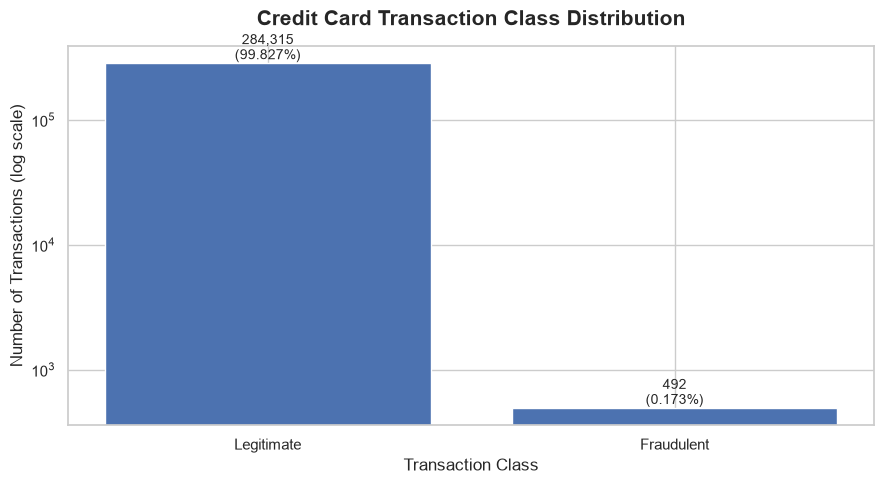

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

class_counts = df["Class"].value_counts().sort_index()
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ["Legitimate", "Fraudulent"],
    class_counts.values
)

ax.set_yscale("log")
ax.set_title(
    "Credit Card Transaction Class Distribution",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions (log scale)")

for bar, count, percentage in zip(
    bars, class_counts.values, class_percentages.values
):
    ax.annotate(
        f"{count:,}\n({percentage:.3f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    figures_dir / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

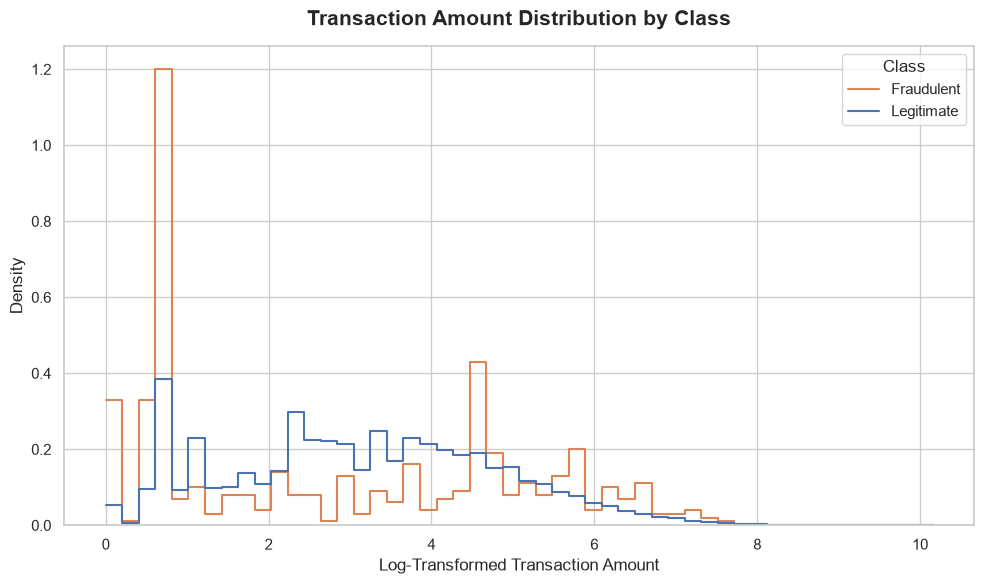

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Log_Amount",
    hue="Class",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    ax=ax
)

ax.set_title(
    "Transaction Amount Distribution by Class",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Log-Transformed Transaction Amount")
ax.set_ylabel("Density")
ax.legend(title="Class", labels=["Fraudulent", "Legitimate"])

plt.tight_layout()

plt.savefig(
    figures_dir / "amount_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

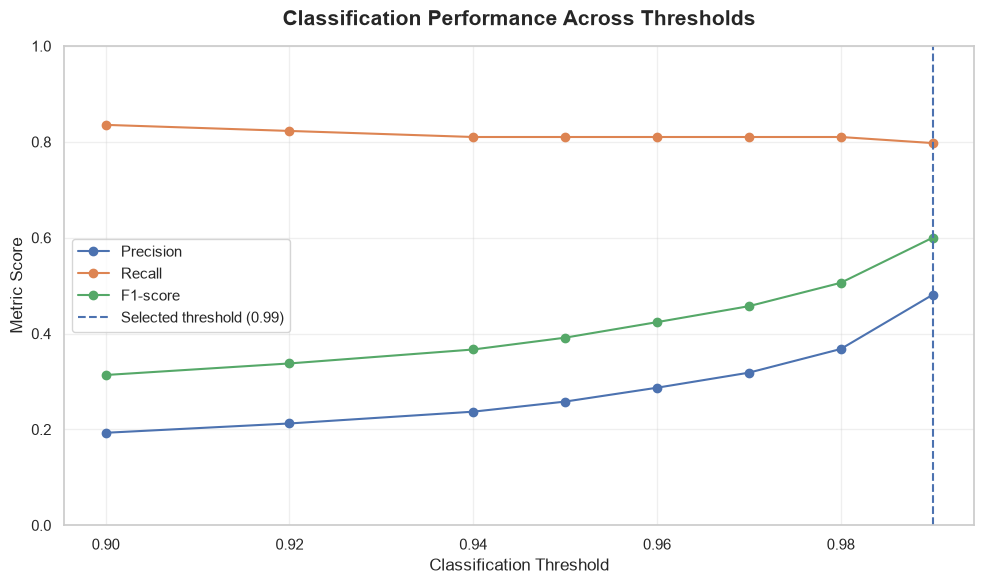

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    fine_threshold_results["Threshold"],
    fine_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    fine_threshold_results["Threshold"],
    fine_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    fine_threshold_results["Threshold"],
    fine_threshold_results["F1"],
    marker="o",
    label="F1-score"
)

ax.axvline(
    x=0.99,
    linestyle="--",
    label="Selected threshold (0.99)"
)

ax.set_title(
    "Classification Performance Across Thresholds",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Metric Score")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "threshold_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

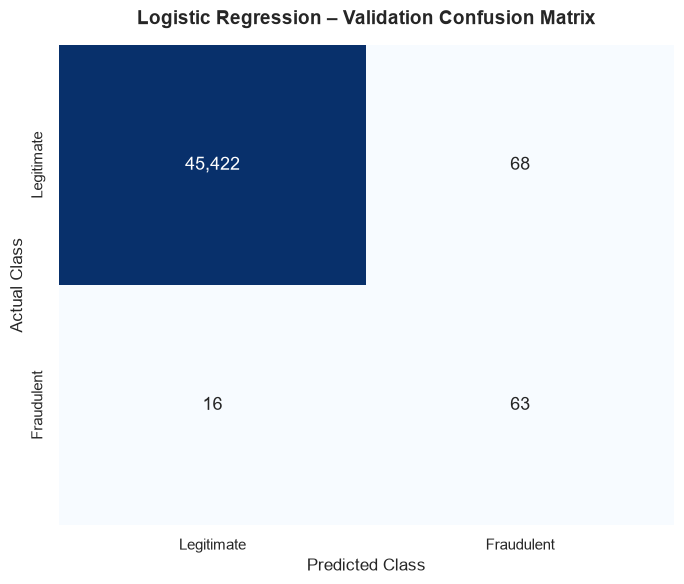

In [19]:
from sklearn.metrics import confusion_matrix

selected_threshold = 0.99

y_val_pred_selected = (
    y_val_proba >= selected_threshold
).astype(int)

cm = confusion_matrix(y_val, y_val_pred_selected)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"],
    annot_kws={"size": 13},
    ax=ax
)

ax.set_title(
    "Logistic Regression – Validation Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    figures_dir / "confusion_matrix_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()